**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053.10 - Ciencia y analítica de datos**

Tecnológico de Monterrey

**Profesora titular:** Dra. Grettel Barceló  
**Profesor tutor:** Mtro. Roberto Antonio Guevara González

**Actividad 7 | Análisis de Componentes Principales (PCA)**

---

**Equipo 5**

- Alejandro Santiago Baca Eyssautier - A01656580
- Andrea Guadalupe Ayala Govea - A01203657
- Arturo Ávila Sánchez - A01841717
- Cristobal Jared Aviles Salgado - A01635702

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [16]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', context='notebook')

**1. Limpieza inicial**

Se carga el archivo, se revisan los tipos de datos, se identifican las columnas que contienen `?`, se sustituyen por valores faltantes y se convierten las variables numéricas que habían sido interpretadas como texto.

In [17]:
ruta_datos = Path('automobile_dataset.csv')
cars_df = pd.read_csv(ruta_datos)

print('Dimensiones iniciales:', cars_df.shape)
print('Tipos de datos iniciales:')
cars_df.info()

conteo_tipos_inicial = cars_df.dtypes.apply(lambda x: 'numérica' if pd.api.types.is_numeric_dtype(x) else 'texto').value_counts()
display(conteo_tipos_inicial.to_frame('columnas'))

columnas_con_interrogacion = [
    columna for columna in cars_df.columns
    if cars_df[columna].astype(str).eq('?').any()
]

display(pd.DataFrame({
    'columna': columnas_con_interrogacion,
    'cantidad_?': [cars_df[columna].astype(str).eq('?').sum() for columna in columnas_con_interrogacion]
}))

cars_df = cars_df.replace('?', np.nan)

columnas_numericas_convertir = [
    'normalized_losses', 'bore', 'stroke', 'horsepower', 'peak_rpm'
]

cars_df[columnas_numericas_convertir] = cars_df[columnas_numericas_convertir].apply(
    pd.to_numeric,
    errors='coerce'
)

print('Tipos de datos después de la conversión:')
cars_df.info()

conteo_tipos_final = cars_df.dtypes.apply(lambda x: 'numérica' if pd.api.types.is_numeric_dtype(x) else 'texto').value_counts()
display(conteo_tipos_final.to_frame('columnas'))
display(cars_df.head())

Dimensiones iniciales: (205, 26)
Tipos de datos iniciales:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders  

,columnas
texto,14
numérica,12


,columna,cantidad_?
0,normalized_losses,41
1,bore,4
2,stroke,4
3,horsepower,2
4,peak_rpm,2


Tipos de datos después de la conversión:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null  

,columnas
numérica,17
texto,9


,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,height,curb_weight,engine_type,num_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6000,168.8000,64.1000,48.8000,2548,dohc,4,130,mpfi,3.4700,2.6800,9.0000,111.0000,"5,000.0000",21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6000,168.8000,64.1000,48.8000,2548,dohc,4,130,mpfi,3.4700,2.6800,9.0000,111.0000,"5,000.0000",21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5000,171.2000,65.5000,52.4000,2823,ohcv,6,152,mpfi,2.6800,3.4700,9.0000,154.0000,"5,000.0000",19,26,16500
3,2,164.0000,audi,gas,std,four,sedan,fwd,front,99.8000,176.6000,66.2000,54.3000,2337,ohc,4,109,mpfi,3.1900,3.4000,10.0000,102.0000,"5,500.0000",24,30,13950
4,2,164.0000,audi,gas,std,four,sedan,4wd,front,99.4000,176.6000,66.4000,54.3000,2824,ohc,5,136,mpfi,3.1900,3.4000,8.0000,115.0000,"5,500.0000",18,22,17450


**Conclusión de la pregunta 1.** El dataframe contiene 205 registros y 26 columnas. Antes de la limpieza, pandas reconocía 12 variables numéricas y 14 de texto. El símbolo `?` aparecía en `normalized_losses`, `bore`, `stroke`, `horsepower` y `peak_rpm`; después de sustituirlo por `NaN` y convertir esas columnas, quedaron 17 variables numéricas y 9 categóricas.

**2. Análisis exploratorio univariado**

Se revisan duplicados, faltantes, estadísticas descriptivas, asimetría, curtosis, histogramas y frecuencias de las variables categóricas.

In [18]:
duplicados = cars_df.duplicated().sum()
porcentaje_faltantes = cars_df.isna().mean().mul(100).sort_values(ascending=False)

print('Registros duplicados:', duplicados)
display(porcentaje_faltantes.to_frame('porcentaje_faltantes'))

num_cols = cars_df.select_dtypes(include='number').columns.tolist()
cat_cols = cars_df.select_dtypes(exclude='number').columns.tolist()

estadisticas_numericas = cars_df[num_cols].describe().T
estadisticas_numericas['asimetria'] = cars_df[num_cols].skew()
estadisticas_numericas['curtosis'] = cars_df[num_cols].kurt()
display(estadisticas_numericas)

estadisticas_categoricas = cars_df[cat_cols].describe(include='all').T
display(estadisticas_categoricas)

for columna in cat_cols:
    display(cars_df[columna].value_counts(dropna=False).rename('frecuencia').to_frame())

Registros duplicados: 0


,porcentaje_faltantes
normalized_losses,20.0000
stroke,1.9512
bore,1.9512
peak_rpm,0.9756
horsepower,0.9756
symboling,0.0000
highway_mpg,0.0000
city_mpg,0.0000
compression_ratio,0.0000
fuel_system,0.0000


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
symboling,205.0000,0.8341,1.2453,-2.0000,0.0000,1.0000,2.0000,3.0000,0.2111,-0.6763
normalized_losses,164.0000,122.0000,35.4422,65.0000,94.0000,115.0000,150.0000,256.0000,0.7660,0.5254
wheel_base,205.0000,98.7566,6.0218,86.6000,94.5000,97.0000,102.4000,120.9000,1.0502,1.0170
length,205.0000,174.0493,12.3373,141.1000,166.3000,173.2000,183.1000,208.1000,0.1560,-0.0829
width,205.0000,65.9078,2.1452,60.3000,64.1000,65.5000,66.9000,72.3000,0.9040,0.7028
height,205.0000,53.7249,2.4435,47.8000,52.0000,54.1000,55.5000,59.8000,0.0631,-0.4438
curb_weight,205.0000,"2,555.5659",520.6802,"1,488.0000","2,145.0000","2,414.0000","2,935.0000","4,066.0000",0.6814,-0.0429
num_cylinders,205.0000,4.3805,1.0809,2.0000,4.0000,4.0000,4.0000,12.0000,2.8175,13.7149
engine_size,205.0000,126.9073,41.6427,61.0000,97.0000,120.0000,141.0000,326.0000,1.9477,5.3057
bore,201.0000,3.3298,0.2735,2.5400,3.1500,3.3100,3.5900,3.9400,0.0200,-0.8289


,count,unique,top,freq
make,205,22,toyota,32
fuel_type,205,2,gas,185
aspiration,205,2,std,168
num_doors,205,2,four,116
body_style,205,5,sedan,96
drive_wheels,205,3,fwd,120
engine_location,205,2,front,202
engine_type,205,7,ohc,148
fuel_system,205,8,mpfi,94


,frecuencia
make,
toyota,32
nissan,18
mazda,17
mitsubishi,13
honda,13
volkswagen,12
subaru,12
peugot,11
volvo,11


...

,frecuencia
body_style,
sedan,96
hatchback,70
wagon,25
hardtop,8
convertible,6


,frecuencia
drive_wheels,
fwd,120
rwd,76
4wd,9


,frecuencia
engine_location,
front,202
rear,3


,frecuencia
engine_type,
ohc,148
ohcf,15
ohcv,13
dohc,12
l,12
rotor,4
dohcv,1


,frecuencia
fuel_system,
mpfi,94
2bbl,66
idi,20
1bbl,11
spdi,9
4bbl,3
mfi,1
spfi,1


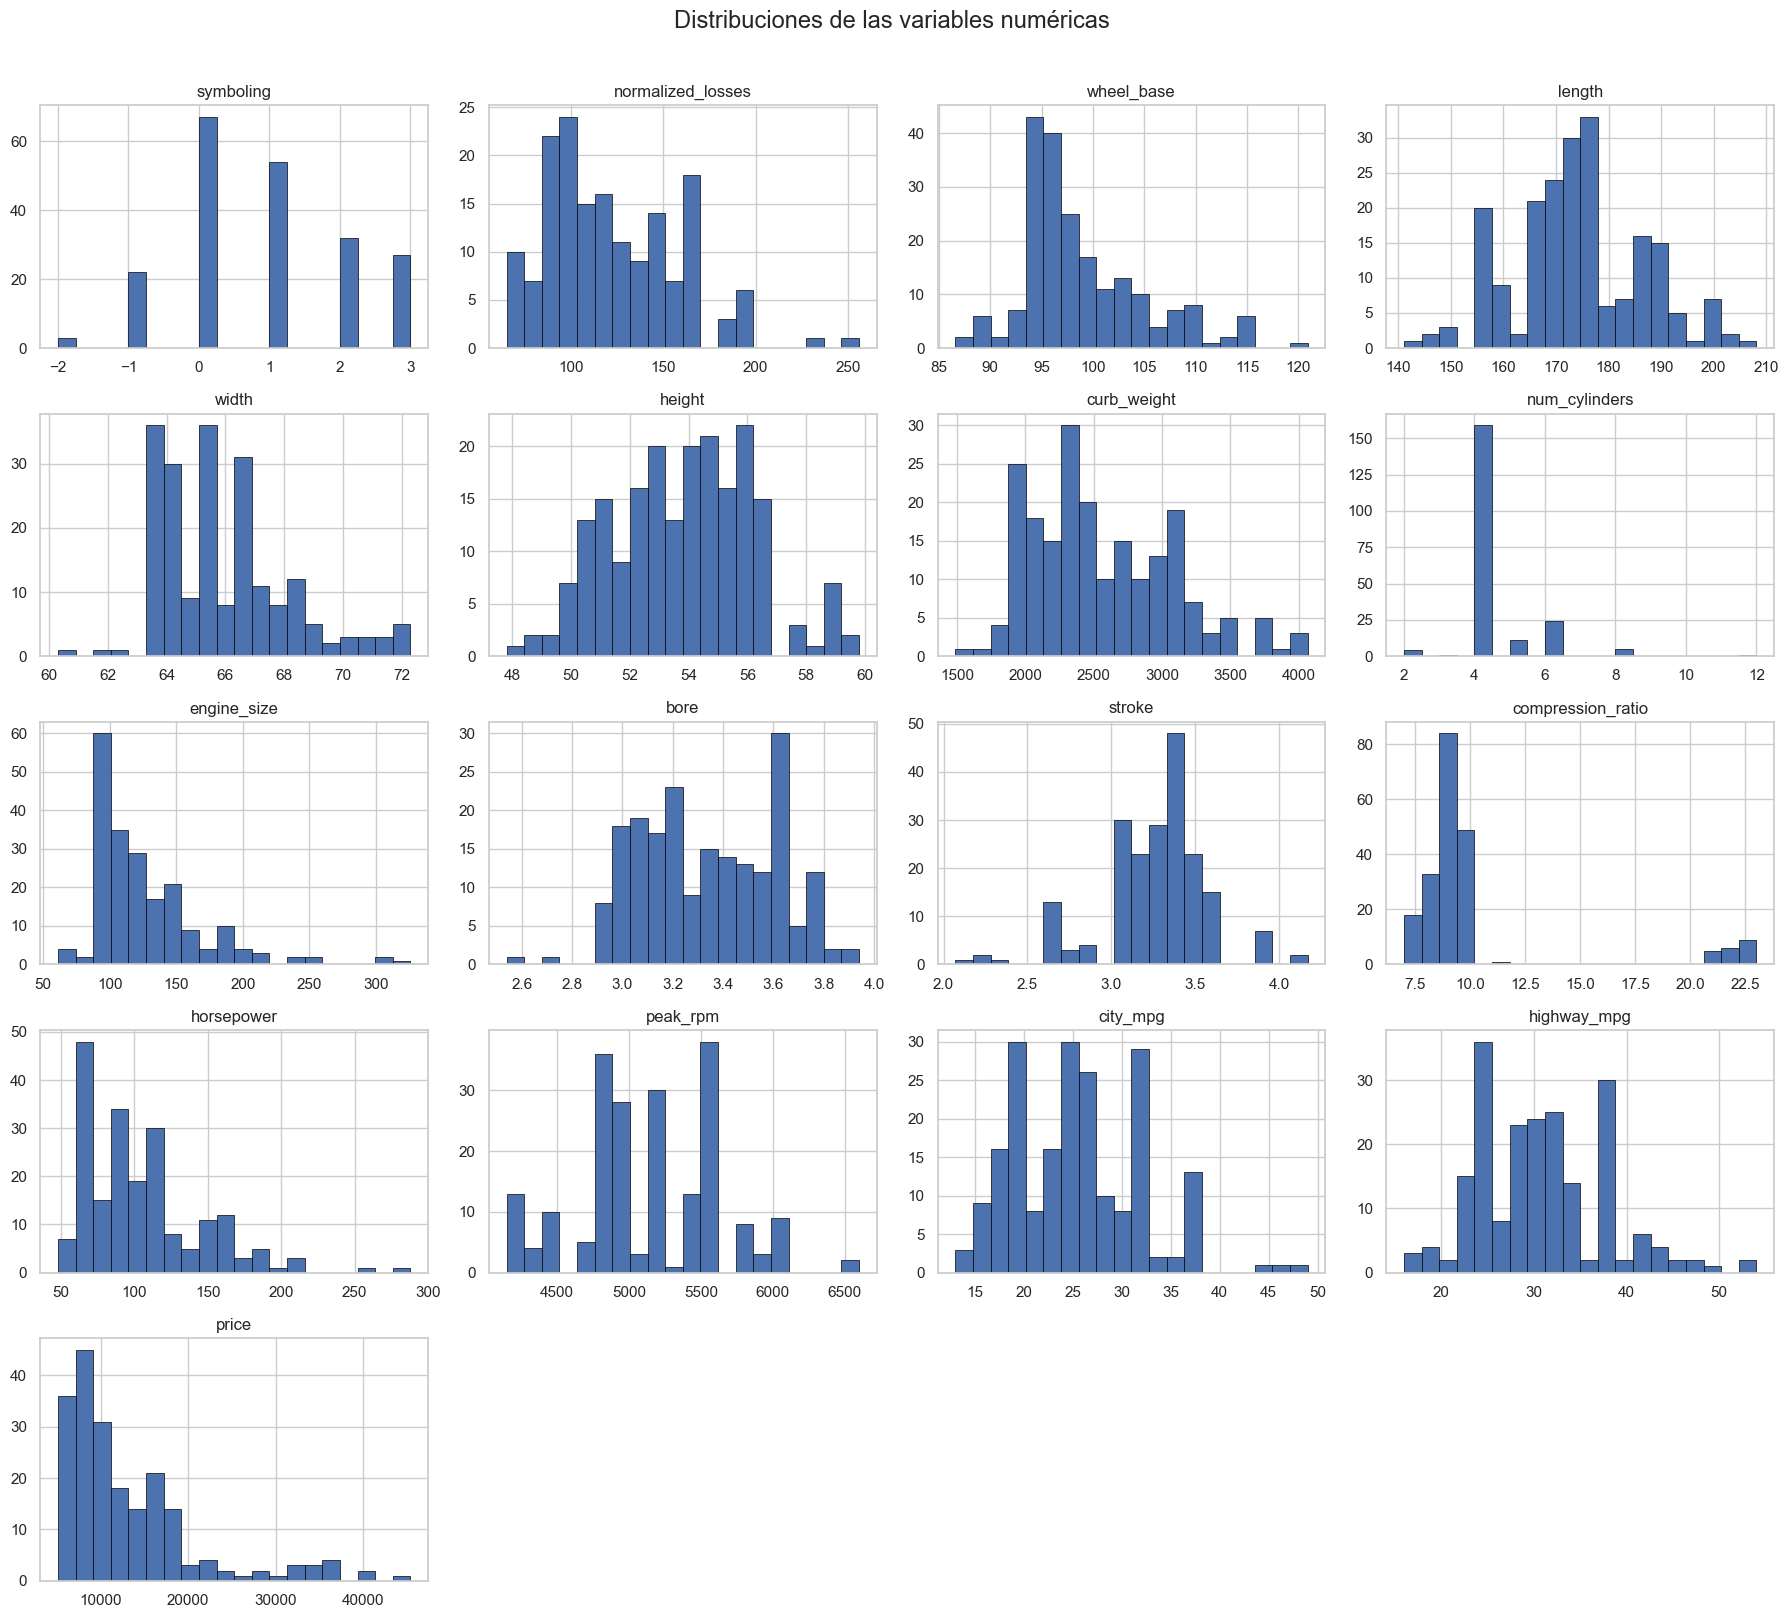

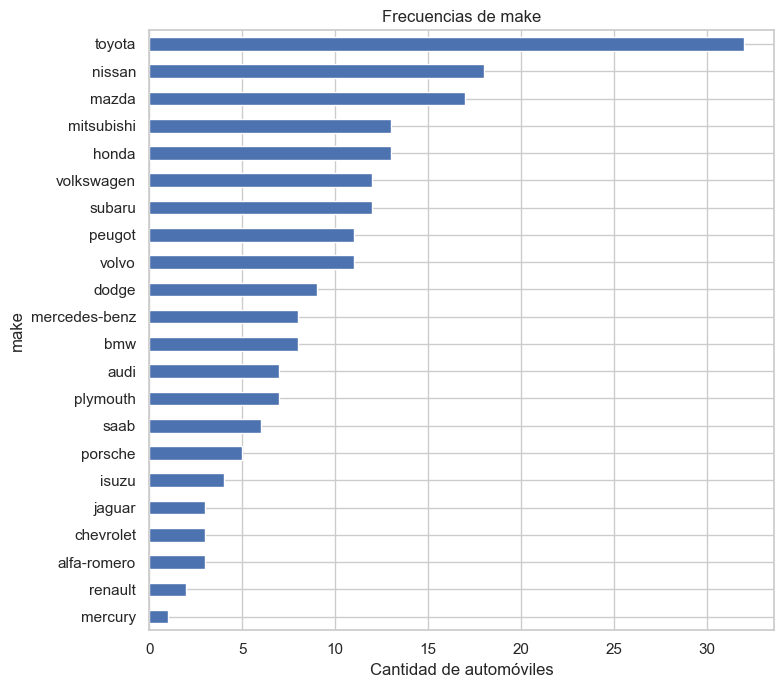

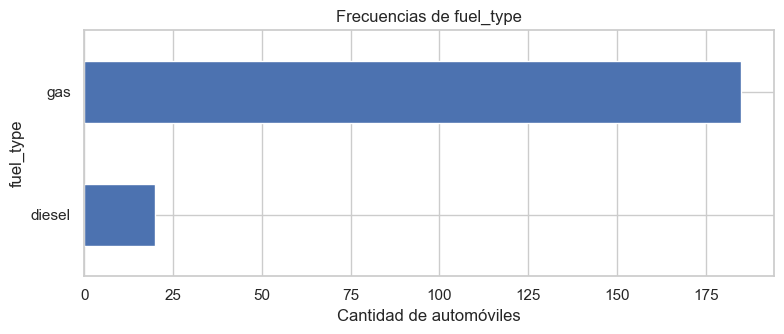

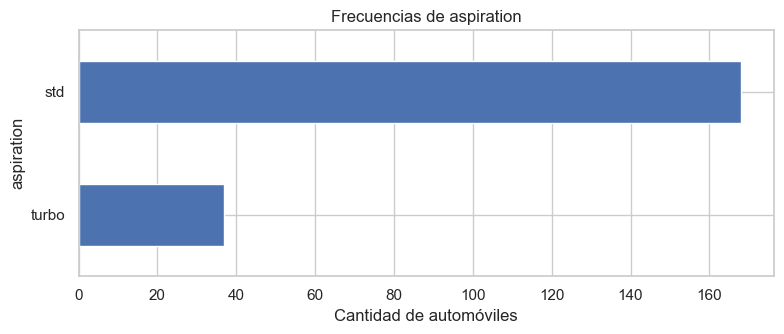

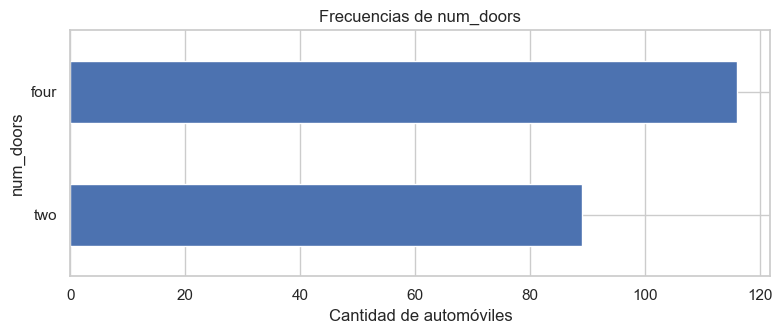

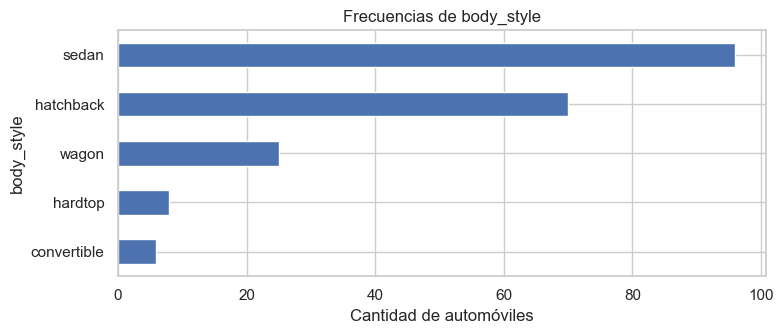

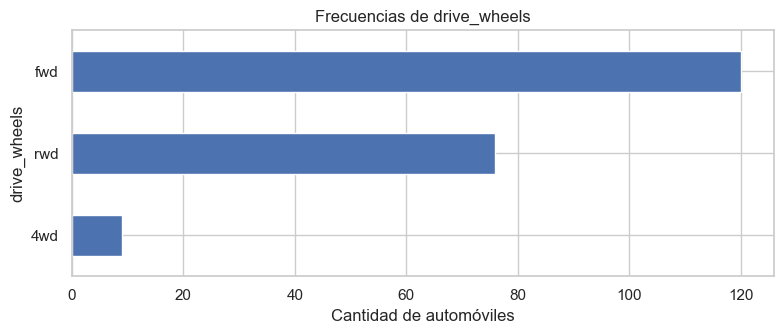

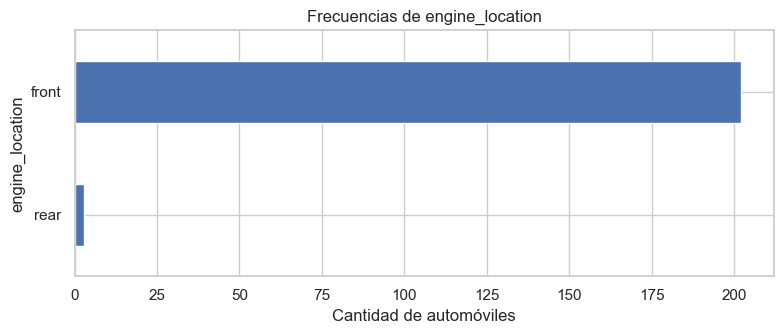

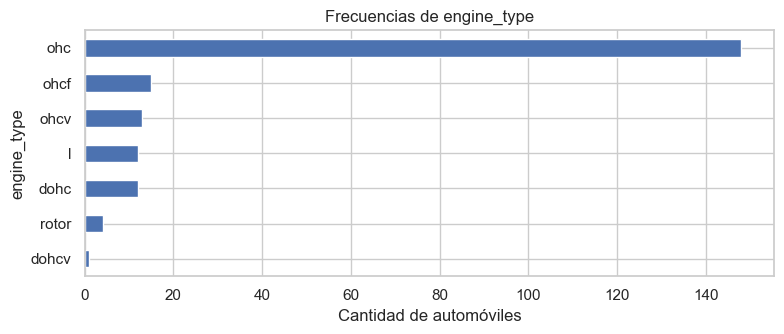

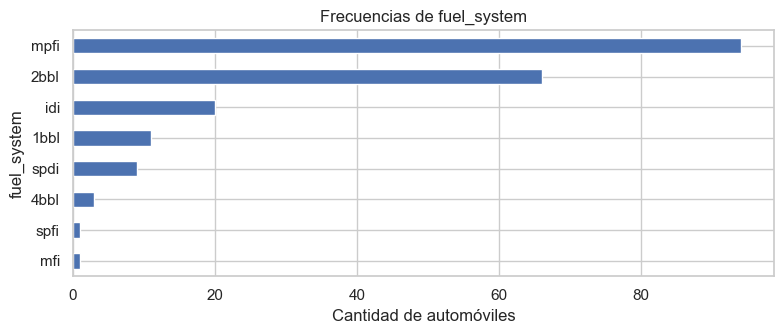

In [19]:
cars_df[num_cols].hist(
    bins=20,
    figsize=(18, 16),
    edgecolor='black',
    linewidth=0.5
)
plt.suptitle('Distribuciones de las variables numéricas', fontsize=17, y=1.01)
plt.tight_layout()
plt.show()

for columna in cat_cols:
    frecuencias = cars_df[columna].value_counts(dropna=False).sort_values()
    alto = max(3.5, len(frecuencias) * 0.32)
    plt.figure(figsize=(8, alto))
    frecuencias.plot(kind='barh')
    plt.title(f'Frecuencias de {columna}')
    plt.xlabel('Cantidad de automóviles')
    plt.ylabel(columna)
    plt.tight_layout()
    plt.show()

**Conclusión de la pregunta 2.** No se encontraron registros duplicados. La mayor ausencia corresponde a `normalized_losses` con 20%, seguida por `bore` y `stroke` con 1.95%, y `horsepower` y `peak_rpm` con 0.98%. Las distribuciones de `price`, `engine_size`, `horsepower` y `num_cylinders` presentan asimetría positiva; predominan automóviles de gasolina, aspiración estándar, motor delantero, tracción delantera y carrocería sedán o hatchback. Toyota es la marca con mayor frecuencia en el conjunto.

**3. Análisis bivariado**

Se construyen los cuatro gráficos solicitados y se interpreta cada relación.

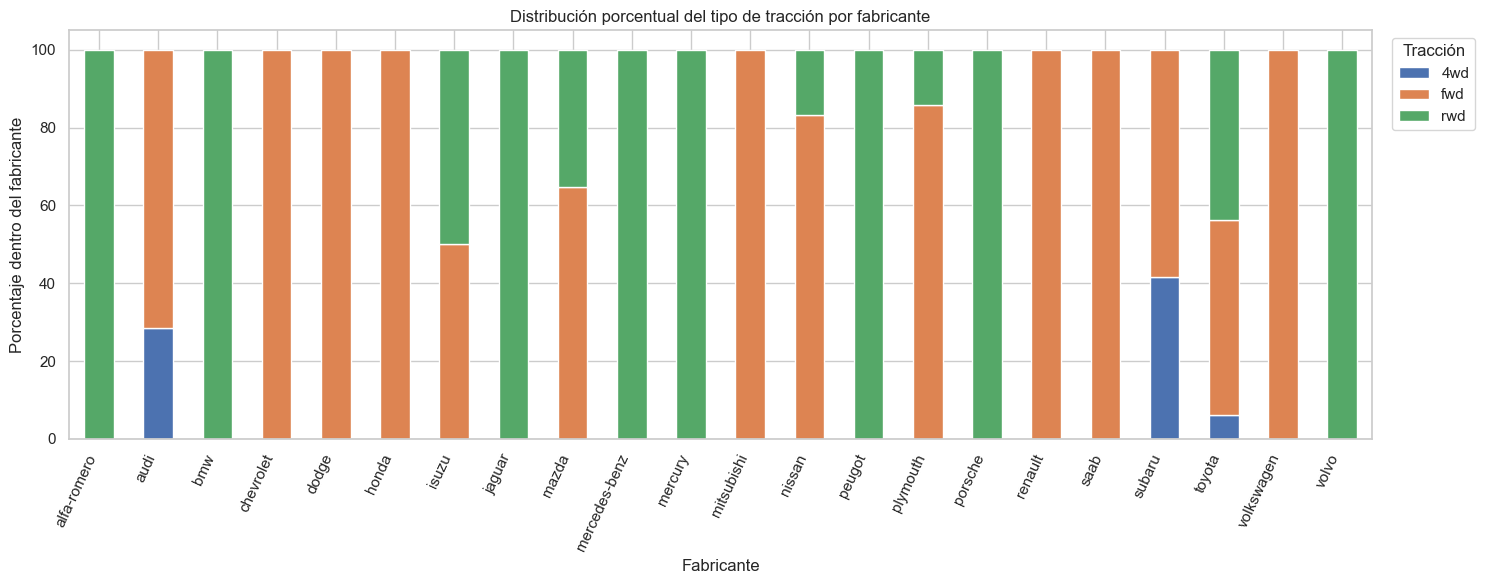

In [20]:
traccion_marca = pd.crosstab(
    cars_df['make'],
    cars_df['drive_wheels'],
    normalize='index'
).mul(100)

traccion_marca.plot(
    kind='bar',
    stacked=True,
    figsize=(15, 6)
)
plt.title('Distribución porcentual del tipo de tracción por fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Porcentaje dentro del fabricante')
plt.legend(title='Tracción', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=65, ha='right')
plt.tight_layout()
plt.show()

**Conclusión del gráfico de tracción.** Se observa una segmentación clara por fabricante. Alfa Romeo, BMW, Jaguar, Mercedes-Benz, Peugeot, Porsche y Volvo aparecen exclusivamente con tracción trasera, mientras que muchas marcas de volumen concentran su oferta en tracción delantera. La tracción en las cuatro ruedas es minoritaria y se concentra en pocos fabricantes, por lo que la elección de tracción parece asociada con el posicionamiento y diseño de cada marca.

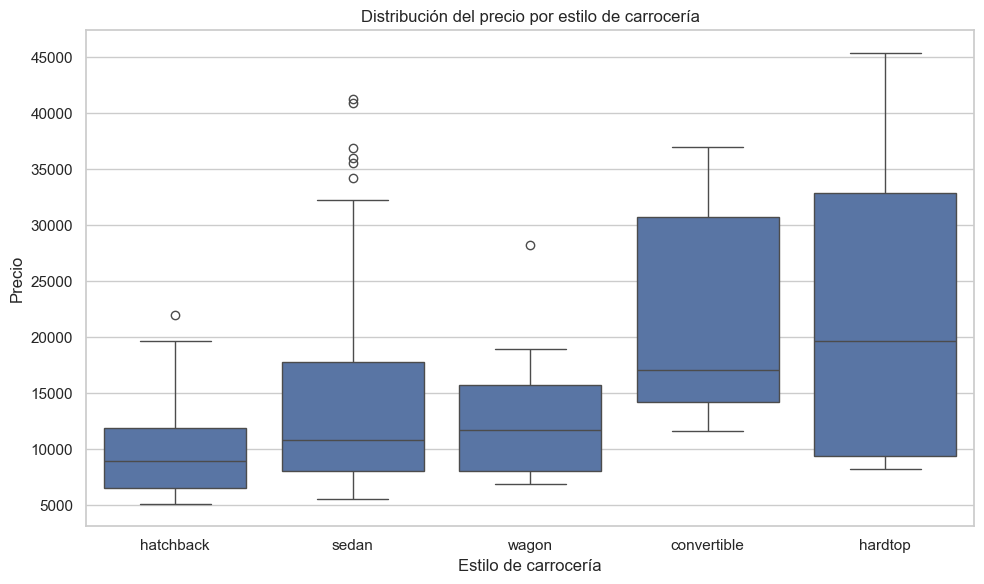

In [21]:
orden_carroceria = cars_df.groupby('body_style')['price'].median().sort_values().index

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=cars_df,
    x='body_style',
    y='price',
    order=orden_carroceria
)
plt.title('Distribución del precio por estilo de carrocería')
plt.xlabel('Estilo de carrocería')
plt.ylabel('Precio')
plt.tight_layout()
plt.show()

**Conclusión del boxplot.** Los hardtop y convertibles presentan las medianas de precio más altas, mientras que los hatchback tienen la mediana más baja. Los sedanes muestran la mayor dispersión y varios valores extremos, porque esta categoría reúne desde vehículos económicos hasta modelos de lujo.

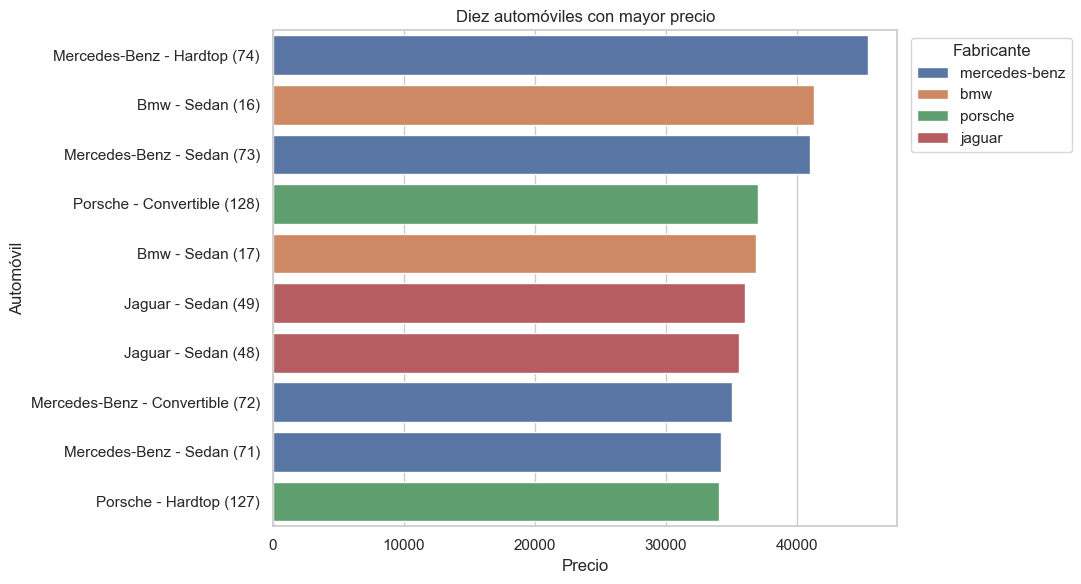

,make,body_style,engine_size,horsepower,price
74,mercedes-benz,hardtop,304,184.0000,45400
16,bmw,sedan,209,182.0000,41315
73,mercedes-benz,sedan,308,184.0000,40960
128,porsche,convertible,194,207.0000,37028
17,bmw,sedan,209,182.0000,36880
49,jaguar,sedan,326,262.0000,36000
48,jaguar,sedan,258,176.0000,35550
72,mercedes-benz,convertible,234,155.0000,35056
71,mercedes-benz,sedan,234,155.0000,34184
127,porsche,hardtop,194,207.0000,34028


In [22]:
autos_mas_caros = cars_df.nlargest(10, 'price').copy()
autos_mas_caros['etiqueta'] = (
    autos_mas_caros['make'].str.title()
    + ' - '
    + autos_mas_caros['body_style'].str.title()
    + ' ('
    + autos_mas_caros.index.astype(str)
    + ')'
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=autos_mas_caros,
    y='etiqueta',
    x='price',
    hue='make',
    dodge=False
)
plt.title('Diez automóviles con mayor precio')
plt.xlabel('Precio')
plt.ylabel('Automóvil')
plt.legend(title='Fabricante', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

display(autos_mas_caros[['make', 'body_style', 'engine_size', 'horsepower', 'price']])

**Conclusión de los automóviles más caros.** Mercedes-Benz domina cuatro de las diez posiciones, seguida por BMW, Jaguar y Porsche con dos vehículos cada una. El precio máximo corresponde a un Mercedes-Benz hardtop de 45,400 dólares. El grupo superior se concentra en fabricantes de lujo y combina motores grandes con potencia elevada.

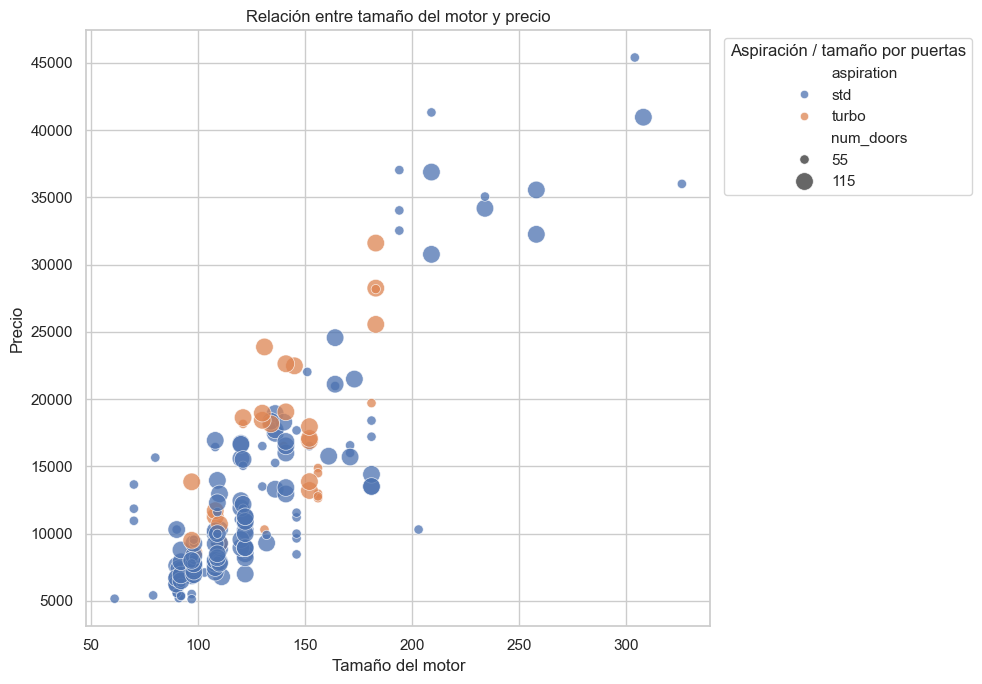

In [23]:
tamano_puertas = cars_df['num_doors'].map({'two': 55, 'four': 115})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=cars_df,
    x='engine_size',
    y='price',
    hue='aspiration',
    size=tamano_puertas,
    sizes=(45, 160),
    alpha=0.75
)
plt.title('Relación entre tamaño del motor y precio')
plt.xlabel('Tamaño del motor')
plt.ylabel('Precio')
plt.legend(title='Aspiración / tamaño por puertas', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Conclusión del diagrama de dispersión.** Existe una relación positiva marcada: a mayor tamaño del motor, mayor precio. Los automóviles turbo tienden a ubicarse en zonas de tamaño y precio superiores; no obstante, la aspiración no explica por sí sola la variación. El número de puertas no produce una separación tan clara como el tamaño del motor.

**4. Matriz de correlación**

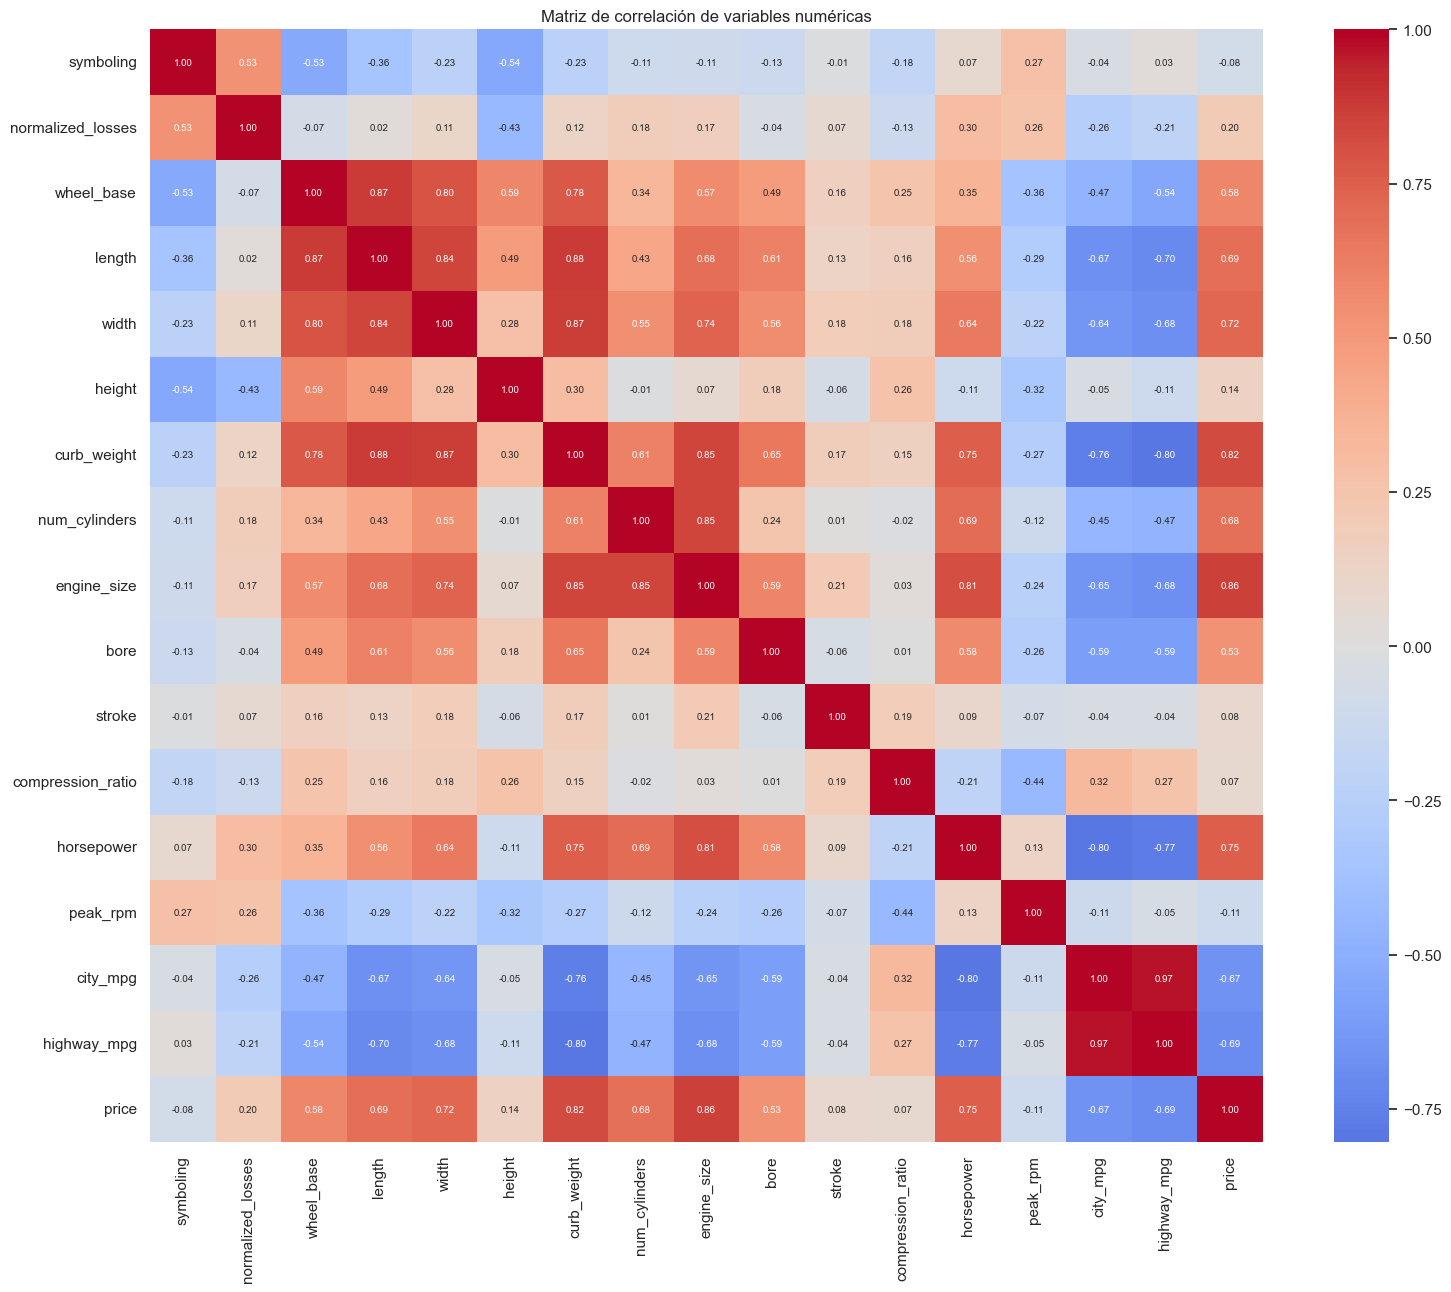

,correlacion_con_price
engine_size,0.8603
curb_weight,0.8198
horsepower,0.7498


In [24]:
matriz_correlacion = cars_df[num_cols].corr()

plt.figure(figsize=(16, 13))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    annot_kws={'size': 7}
)
plt.title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.show()

correlaciones_precio = (
    matriz_correlacion['price']
    .drop('price')
    .sort_values(key=abs, ascending=False)
)

top_tres_precio = correlaciones_precio.head(3)
display(top_tres_precio.rename('correlacion_con_price').to_frame())

**Conclusión de la pregunta 4.** Las tres variables más correlacionadas con `price` son `engine_size` (0.8603), `curb_weight` (0.8198) y `horsepower` (0.7498). El resultado es coherente: el precio aumenta conforme crecen la capacidad mecánica, la potencia y el tamaño/peso general del automóvil. También se observan relaciones negativas importantes entre precio y rendimiento de combustible, especialmente `highway_mpg`.

**5. Imputación y escalamiento**

In [25]:
y = cars_df['price'].copy()
X = cars_df.select_dtypes(include='number').drop(columns='price').copy()

numero_componentes_posibles = X.shape[1]
print('Predictores numéricos:', X.shape[1])
print('Componentes principales posibles:', numero_componentes_posibles)

imputador = SimpleImputer(strategy='median')
X_imputado = pd.DataFrame(
    imputador.fit_transform(X),
    columns=X.columns,
    index=X.index
)

escalador = StandardScaler()
X_escalado = pd.DataFrame(
    escalador.fit_transform(X_imputado),
    columns=X.columns,
    index=X.index
)

display(X_escalado.describe().T[['mean', 'std', 'min', 'max']])

Predictores numéricos: 16
Componentes principales posibles: 16


,mean,std,min,max
symboling,0.0000,1.0024,-2.2814,1.7435
normalized_losses,0.0000,1.0024,-1.7524,4.2676
wheel_base,-0.0000,1.0024,-2.0237,3.6862
length,0.0000,1.0024,-2.6772,2.7667
width,0.0000,1.0024,-2.6205,2.9871
height,-0.0000,1.0024,-2.4307,2.4923
curb_weight,0.0000,1.0024,-2.0553,2.9080
num_cylinders,-0.0000,1.0024,-2.2078,7.0668
engine_size,0.0000,1.0024,-1.5866,4.7927
bore,0.0000,1.0024,-2.9215,2.2600


**Conclusión de la pregunta 5.** Se generarán hasta 16 componentes principales, uno por predictor numérico. Se utilizó imputación por mediana porque varias variables presentan asimetría y posibles valores extremos; la mediana evita que esos casos desplacen el valor imputado. Posteriormente se aplicó `StandardScaler` para centrar las variables en cero y darles varianza comparable, impidiendo que magnitudes como peso, RPM o pérdidas normalizadas dominen el PCA por su escala.

**6. Aplicación de PCA**

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.9185,-2.3972,-0.4105,1.4166,-1.8228,1.2032,0.3697,0.2888,-1.0884,-0.3477,-0.4746,0.2676,-0.2736,0.3623,0.1852,0.0039
1,-0.9185,-2.3972,-0.4105,1.4166,-1.8228,1.2032,0.3697,0.2888,-1.0884,-0.3477,-0.4746,0.2676,-0.2736,0.3623,0.1852,0.0039
2,0.6344,-1.3727,0.8725,0.9982,1.8347,-0.7748,-0.5151,1.3705,-1.1308,-1.0137,0.5030,0.6571,0.1750,-0.0085,0.1186,-0.1117
3,-0.3615,-0.9192,0.4516,-1.4891,-0.2699,-0.7899,0.0005,0.4000,0.2933,0.1681,0.0392,-0.0228,-0.0789,-0.3918,0.0093,0.0536
4,1.1724,-1.7950,0.1838,-1.0838,0.1135,-0.8619,-0.3539,0.8702,0.0154,-0.4471,-0.0554,-0.4161,-0.0494,0.0794,-0.1984,0.0463


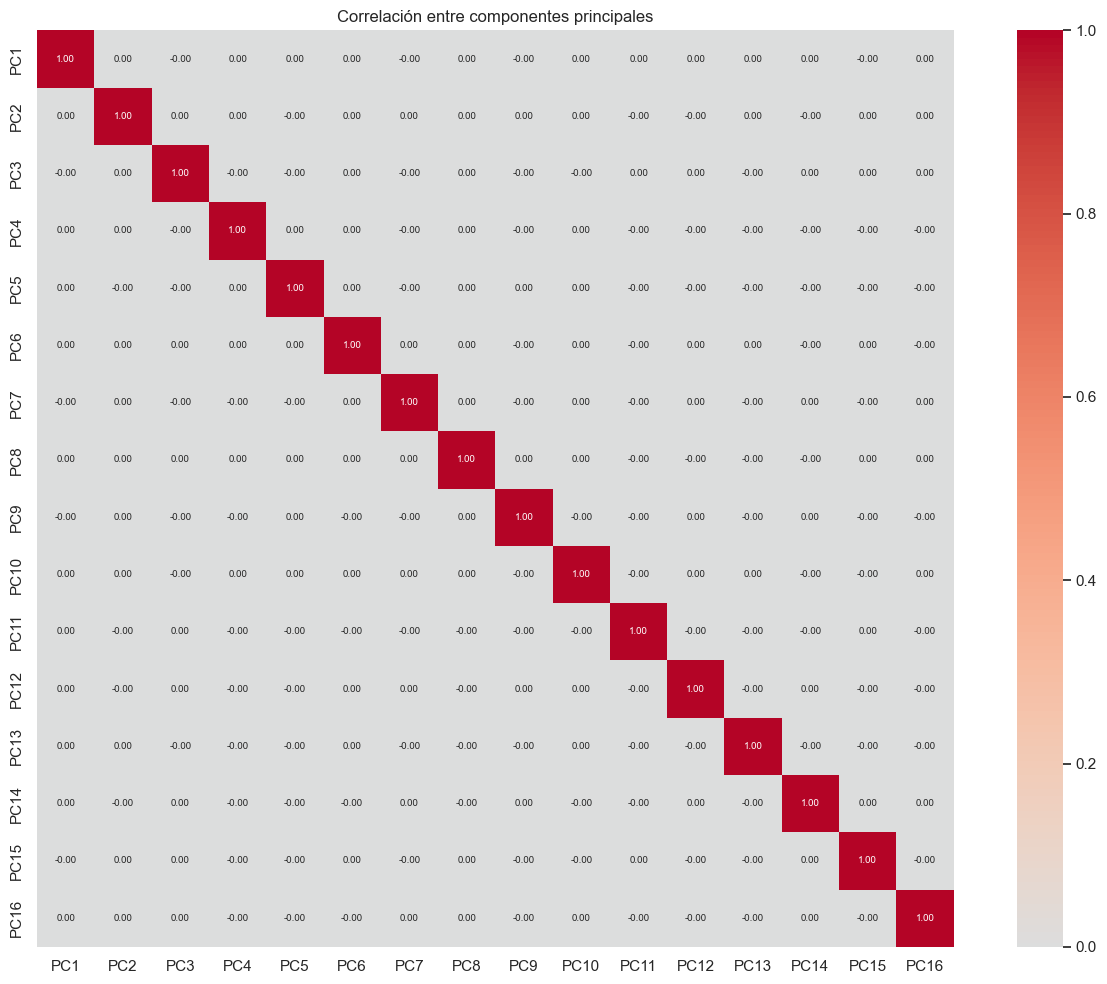

In [26]:
modelo_pca = PCA()
proyeccion_pca = modelo_pca.fit_transform(X_escalado)

nombres_pc = [f'PC{i}' for i in range(1, proyeccion_pca.shape[1] + 1)]
pca_df = pd.DataFrame(
    proyeccion_pca,
    columns=nombres_pc,
    index=cars_df.index
)

display(pca_df.head())

plt.figure(figsize=(13, 10))
sns.heatmap(
    pca_df.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    annot_kws={'size': 7}
)
plt.title('Correlación entre componentes principales')
plt.tight_layout()
plt.show()

**Conclusión de la pregunta 6.** La matriz de correlación entre componentes es prácticamente una matriz identidad: las correlaciones fuera de la diagonal son cercanas a cero. Esto confirma la propiedad de ortogonalidad del PCA y muestra que la información fue reorganizada en nuevas dimensiones linealmente independientes.

**7. Varianza explicada y selección de componentes**

,componente,varianza_explicada,varianza_acumulada
0,PC1,0.4455,0.4455
1,PC2,0.1793,0.6248
2,PC3,0.0858,0.7105
3,PC4,0.0644,0.7749
4,PC5,0.0574,0.8323
5,PC6,0.0478,0.8801
6,PC7,0.0325,0.9126
7,PC8,0.0273,0.9398
8,PC9,0.0194,0.9592
9,PC10,0.0155,0.9748


Número mínimo de componentes para superar 90%: 7
Varianza acumulada: 0.9125751641804416


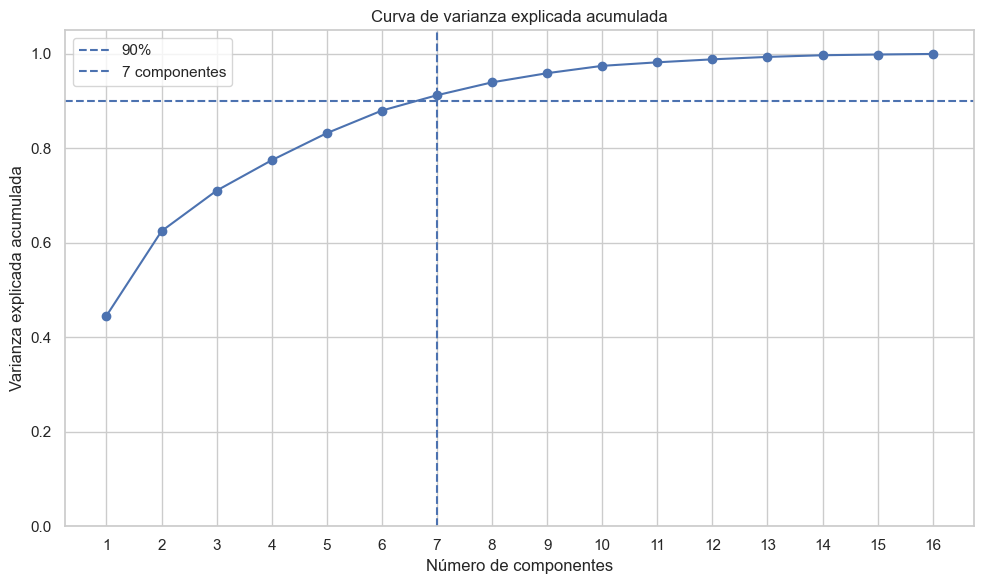

In [27]:
varianza_explicada = modelo_pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

resumen_varianza = pd.DataFrame({
    'componente': nombres_pc,
    'varianza_explicada': varianza_explicada,
    'varianza_acumulada': varianza_acumulada
})
display(resumen_varianza)

n_componentes_90 = int(np.argmax(varianza_acumulada > 0.90) + 1)
print('Número mínimo de componentes para superar 90%:', n_componentes_90)
print('Varianza acumulada:', varianza_acumulada[n_componentes_90 - 1])

plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker='o'
)
plt.axhline(0.90, linestyle='--', label='90%')
plt.axvline(n_componentes_90, linestyle='--', label=f'{n_componentes_90} componentes')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.ylim(0, 1.05)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('Curva de varianza explicada acumulada')
plt.legend()
plt.tight_layout()
plt.show()

**Conclusión de la pregunta 7.** Los primeros 7 componentes explican 91.26% de la varianza total, por lo que constituyen el conjunto mínimo que supera el umbral de 90%. PC1 concentra 44.55% y PC2 agrega 17.93%; después, cada componente aporta incrementos menores. La reducción conserva la mayor parte de la información usando menos de la mitad de las variables numéricas originales.

**8. Interpretación de componentes**

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
symboling,-0.0974,-0.4028,0.2654,-0.0717,-0.3659,0.1735,0.1278
normalized_losses,0.0157,-0.3308,0.3083,-0.3431,-0.3761,-0.4921,-0.3226
wheel_base,0.2978,0.2646,-0.0295,-0.2283,-0.0044,-0.1835,-0.1063
length,0.3376,0.1387,-0.0439,-0.1941,-0.0735,-0.0822,-0.0087
width,0.3342,0.0552,0.1086,-0.0977,-0.0164,-0.1072,0.1399
height,0.1139,0.4217,-0.2825,-0.1861,-0.0167,-0.2140,-0.0026
curb_weight,0.3619,0.0224,0.0803,-0.0251,-0.0423,-0.0135,0.0612
num_cylinders,0.2452,-0.1141,0.1767,0.5521,0.2367,-0.3541,-0.0683
engine_size,0.3301,-0.0816,0.1989,0.2955,0.1088,0.0156,-0.0731
bore,0.2627,0.0031,-0.1382,0.0407,-0.3730,0.5119,0.1262


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
bore,NaN,NaN,NaN,NaN,-0.3730,0.5119,NaN
compression_ratio,NaN,0.3609,0.4902,NaN,NaN,NaN,0.6141
curb_weight,0.3619,NaN,NaN,NaN,NaN,NaN,NaN
engine_size,0.3301,NaN,NaN,0.2955,NaN,NaN,NaN
height,NaN,0.4217,-0.2825,NaN,NaN,NaN,NaN
highway_mpg,-0.3174,NaN,NaN,NaN,NaN,NaN,NaN
horsepower,NaN,NaN,NaN,NaN,NaN,NaN,0.2239
length,0.3376,NaN,NaN,NaN,NaN,NaN,NaN
normalized_losses,NaN,-0.3308,0.3083,-0.3431,-0.3761,-0.4921,-0.3226
num_cylinders,NaN,NaN,NaN,0.5521,NaN,-0.3541,NaN


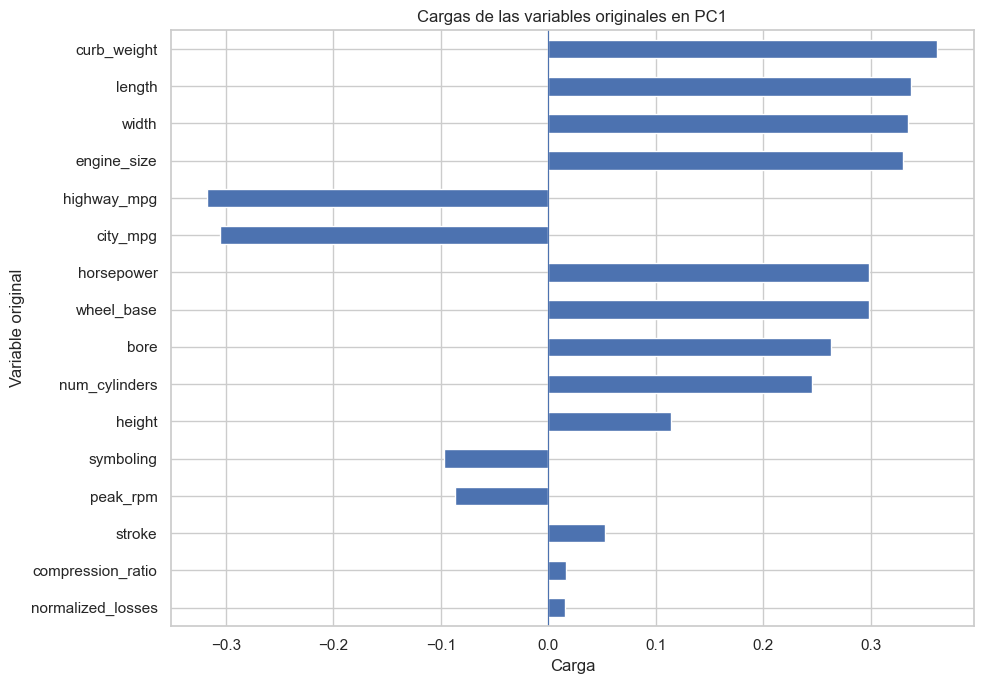

In [28]:
cargas = pd.DataFrame(
    modelo_pca.components_.T,
    index=X.columns,
    columns=nombres_pc
)

cargas_seleccionadas = cargas.iloc[:, :n_componentes_90]
display(cargas_seleccionadas)

principales_por_componente = {}
for componente in cargas_seleccionadas.columns:
    principales_por_componente[componente] = (
        cargas_seleccionadas[componente]
        .sort_values(key=abs, ascending=False)
        .head(5)
    )

display(pd.DataFrame(principales_por_componente))

cargas_pc1 = cargas_seleccionadas['PC1'].sort_values(key=abs)

plt.figure(figsize=(10, 7))
cargas_pc1.plot(kind='barh')
plt.axvline(0, linewidth=0.8)
plt.title('Cargas de las variables originales en PC1')
plt.xlabel('Carga')
plt.ylabel('Variable original')
plt.tight_layout()
plt.show()

**Conclusión de la pregunta 8.** PC1 representa principalmente la dimensión general de tamaño, masa y potencia del automóvil: recibe cargas positivas altas de `curb_weight`, `length`, `width`, `engine_size`, `horsepower` y `wheel_base`, y cargas negativas de `city_mpg` y `highway_mpg`. Por tanto, valores altos de PC1 describen vehículos grandes, pesados y potentes, pero menos eficientes en combustible. PC2 separa principalmente altura, riesgo (`symboling`), RPM y relación de compresión; los componentes posteriores capturan contrastes más específicos entre geometría del motor, cilindros, pérdidas normalizadas y desempeño.

**9. Codificación de variables categóricas**

In [29]:
variables_categoricas = cars_df.select_dtypes(exclude='number').columns.tolist()

codificador_ohe = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',
    sparse_output=False
)

matriz_ohe = codificador_ohe.fit_transform(cars_df[variables_categoricas])
nombres_ohe = codificador_ohe.get_feature_names_out(variables_categoricas)

ohe_df = pd.DataFrame(
    matriz_ohe,
    columns=nombres_ohe,
    index=cars_df.index
)

print('Variables categóricas originales:', len(variables_categoricas))
print('Variables dummy generadas:', ohe_df.shape[1])
display(ohe_df.head())

Variables categóricas originales: 9
Variables dummy generadas: 44


,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,make_mitsubishi,make_nissan,make_peugot,make_plymouth,make_porsche,make_renault,make_saab,make_subaru,make_toyota,make_volkswagen,make_volvo,fuel_type_gas,aspiration_turbo,num_doors_two,body_style_hardtop,body_style_hatchback,body_style_sedan,body_style_wagon,drive_wheels_fwd,drive_wheels_rwd,engine_location_rear,engine_type_dohcv,engine_type_l,engine_type_ohc,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi
0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
3,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
4,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000


**Conclusión de la pregunta 9.** Las nueve variables categóricas generaron 44 variables dummy. `drop='first'` elimina una categoría de referencia por variable y reduce la dependencia lineal exacta entre columnas, mientras que `handle_unknown='ignore'` hace el proceso más robusto ante categorías no vistas en una aplicación posterior.

**10. Construcción y almacenamiento del conjunto final**

In [30]:
pca_seleccionado_df = pca_df.iloc[:, :n_componentes_90].copy()

conjunto_final = pd.concat(
    [
        pca_seleccionado_df.reset_index(drop=True),
        ohe_df.reset_index(drop=True),
        y.reset_index(drop=True).rename('price')
    ],
    axis=1
)

archivo_salida = 'automobile_pca_dataset_equipo5.csv'
conjunto_final.to_csv(archivo_salida, index=False)

print('Dimensiones del conjunto final:', conjunto_final.shape)
print('Valores faltantes:', conjunto_final.isna().sum().sum())
print('Archivo generado:', archivo_salida)
display(conjunto_final.head())
display(conjunto_final.describe().T)

Dimensiones del conjunto final: (205, 52)
Valores faltantes: 0
Archivo generado: automobile_pca_dataset_equipo5.csv


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,make_mitsubishi,make_nissan,make_peugot,make_plymouth,make_porsche,make_renault,make_saab,make_subaru,make_toyota,make_volkswagen,make_volvo,fuel_type_gas,aspiration_turbo,num_doors_two,body_style_hardtop,body_style_hatchback,body_style_sedan,body_style_wagon,drive_wheels_fwd,drive_wheels_rwd,engine_location_rear,engine_type_dohcv,engine_type_l,engine_type_ohc,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.9185,-2.3972,-0.4105,1.4166,-1.8228,1.2032,0.3697,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,13495
1,-0.9185,-2.3972,-0.4105,1.4166,-1.8228,1.2032,0.3697,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,16500
2,0.6344,-1.3727,0.8725,0.9982,1.8347,-0.7748,-0.5151,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,16500
3,-0.3615,-0.9192,0.4516,-1.4891,-0.2699,-0.7899,0.0005,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,13950
4,1.1724,-1.7950,0.1838,-1.0838,0.1135,-0.8619,-0.3539,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,17450


,count,mean,std,min,25%,50%,75%,max
PC1,205.0000,-0.0000,2.6764,-6.9073,-2.0759,-0.2417,1.9723,8.7273
PC2,205.0000,-0.0000,1.6978,-4.1980,-0.9420,0.1263,0.8438,3.9061
PC3,205.0000,0.0000,1.1742,-2.9340,-0.6568,-0.1695,0.8028,2.9789
PC4,205.0000,-0.0000,1.0173,-2.5035,-0.5440,-0.1950,0.5895,6.0239
PC5,205.0000,0.0000,0.9603,-2.6592,-0.6569,0.1437,0.6259,2.1688
PC6,205.0000,-0.0000,0.8767,-3.1882,-0.5105,0.0005,0.4640,2.4916
PC7,205.0000,0.0000,0.7229,-2.2499,-0.4630,-0.1132,0.4356,2.3427
make_audi,205.0000,0.0341,0.1820,0.0000,0.0000,0.0000,0.0000,1.0000
make_bmw,205.0000,0.0390,0.1941,0.0000,0.0000,0.0000,0.0000,1.0000
make_chevrolet,205.0000,0.0146,0.1204,0.0000,0.0000,0.0000,0.0000,1.0000


**Conclusión de la pregunta 10.** El conjunto final contiene 205 registros y 52 columnas: 7 componentes principales, 44 variables categóricas codificadas y la variable objetivo `price`. No contiene valores faltantes y fue almacenado en `automobile_pca_dataset_equipo5.csv`, quedando listo para utilizarse en etapas posteriores de modelado supervisado.